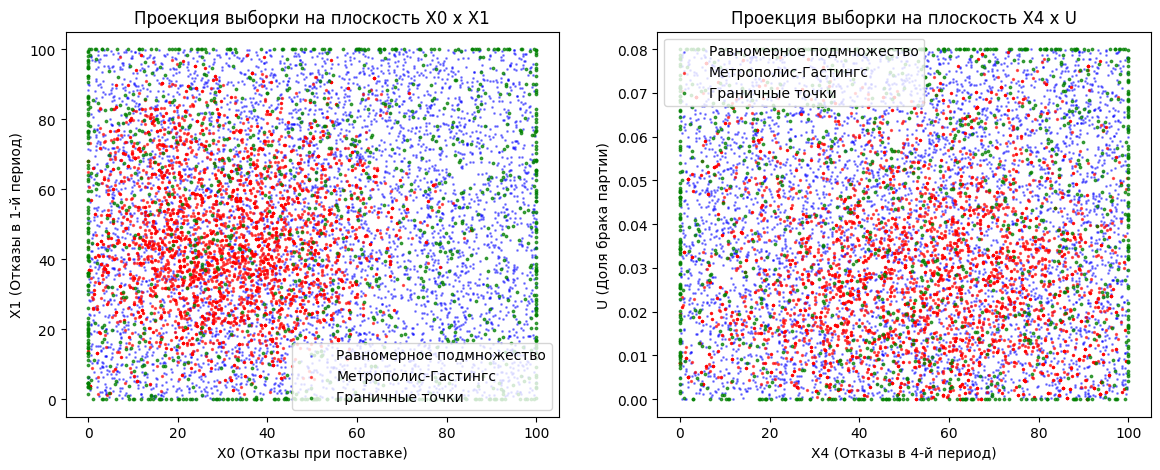

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Фиксация случайных чисел для воспроизводимости
SEED = 42
np.random.seed(SEED)

# Границы шестимерной области D
a_bounds = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0])
b_bounds = np.array([100.0, 100.0, 100.0, 100.0, 100.0, 0.08])

def g_function(xi):
    """ Вычисление ненормированной совместной плотности (Формула 3) """
    xi = np.atleast_2d(xi)
    x0, x1, x2 = xi[:, 0], xi[:, 1], xi[:, 2]
    u = xi[:, 5]

    mu = np.array([30.0, 42.0, 45.0, 48.0, 52.0])
    sigma = np.array([12.0, 15.0, 16.0, 18.0, 20.0])

    exp_sum = 0.0
    for i in range(5):
        exp_sum += (xi[:, i] - mu[i])**2 / (2.0 * sigma[i]**2)
    exp_sum += (u - 0.02)**2 / (2.0 * 0.015**2)

    exp_part = np.exp(-exp_sum)
    cos_part = 1.0 + 0.15 * np.cos(0.04 * (x1 + x2 - 2.0 * x0))
    return exp_part * cos_part

def metropolis_hastings(n_samples, rho=0.4, burn_in=5000):
    """ Алгоритм Метрополиса-Гастингса для генерации точек в зоне высокой плотности """
    samples = []
    # Начальное состояние - центр распределения
    x_current = np.array([30.0, 42.0, 45.0, 48.0, 52.0, 0.02])
    g_current = g_function(x_current)[0]

    # Шаги блуждания для каждой из 6 осей
    step_sizes = np.array([6.0, 7.5, 8.0, 9.0, 10.0, 0.007])

    for i in range(n_samples + burn_in):
        proposal = x_current + np.random.normal(0, 1, size=6) * step_sizes
        # Проверка нахождения внутри гиперпараллелепипеда D
        if np.all(proposal >= a_bounds) and np.all(proposal <= b_bounds):
            g_prop = g_function(proposal)[0]
            # Учитываем параметр rho для управления концентрацией
            alpha = min(1.0, (g_prop / g_current)**rho if g_current > 0 else 1.0)
            if np.random.uniform(0, 1) < alpha:
                x_current = proposal
                g_current = g_prop
        if i >= burn_in:
            samples.append(x_current.copy())
    return np.array(samples)

def generate_combined_sampling(N, border_ratio=0.10, rho=0.4):
    """ Функция формирования объединенного пространства точек """
    N_border = int(N * border_ratio)
    N_rest = N - N_border
    N_mg = int(rho * N_rest)
    N_uniform = N_rest - N_mg

    # 1. Равномерные точки
    X_uniform = np.random.uniform(a_bounds, b_bounds, (N_uniform, 6))
    # 2. Точки Метрополиса-Гастингса
    X_mg = metropolis_hastings(N_mg, rho=rho)
    # 3. Граничные точки
    X_border = np.random.uniform(a_bounds, b_bounds, (N_border, 6))
    for i in range(N_border):
        dim = np.random.randint(0, 6)
        X_border[i, dim] = np.random.choice([a_bounds[dim], b_bounds[dim]])

    return X_uniform, X_mg, X_border

# Генерация тестовой структуры
X_u, X_m, X_b = generate_combined_sampling(N=10000, border_ratio=0.12, rho=0.4)

# Отрисовка проекций структуры данных
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X_u[:, 0], X_u[:, 1], s=1, color='blue', alpha=0.4, label='Равномерное подмножество')
ax[0].scatter(X_m[:, 0], X_m[:, 1], s=2, color='red', alpha=0.6, label='Метрополис-Гастингс')
ax[0].scatter(X_b[:, 0], X_b[:, 1], s=3, color='green', alpha=0.7, label='Граничные точки')
ax[0].set_title('Проекция выборки на плоскость X0 x X1')
ax[0].set_xlabel('X0 (Отказы при поставке)'); ax[0].set_ylabel('X1 (Отказы в 1-й период)'); ax[0].legend()

ax[1].scatter(X_u[:, 4], X_u[:, 5], s=1, color='blue', alpha=0.4, label='Равномерное подмножество')
ax[1].scatter(X_m[:, 4], X_m[:, 5], s=2, color='red', alpha=0.6, label='Метрополис-Гастингс')
ax[1].scatter(X_b[:, 4], X_b[:, 5], s=3, color='green', alpha=0.7, label='Граничные точки')
ax[1].set_title('Проекция выборки на плоскость X4 x U')
ax[1].set_xlabel('X4 (Отказы в 4-й период)'); ax[1].set_ylabel('U (Доля брака партии)'); ax[1].legend()
plt.show()


Epoch 1/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.0069 - mae: 0.0404 - val_loss: 0.0017 - val_mae: 0.0100
Epoch 2/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0012 - mae: 0.0108 - val_loss: 0.0017 - val_mae: 0.0130
Epoch 3/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - mae: 0.0110 - val_loss: 0.0017 - val_mae: 0.0126
Epoch 4/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0012 - mae: 0.0110 - val_loss: 0.0017 - val_mae: 0.0098
Epoch 5/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0012 - mae: 0.0108 - val_loss: 0.0017 - val_mae: 0.0120
Epoch 6/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0012 - mae: 0.0110 - val_loss: 0.0017 - val_mae: 0.0151
Epoch 7/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0012 - mae: 0.0116 - val_loss: 0.0017 - val_mae: 0.0131
Epoch 8/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0012 - mae: 0.0114 - val_loss: 0.0017 - val_mae: 0.0119
Epoch 9/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms

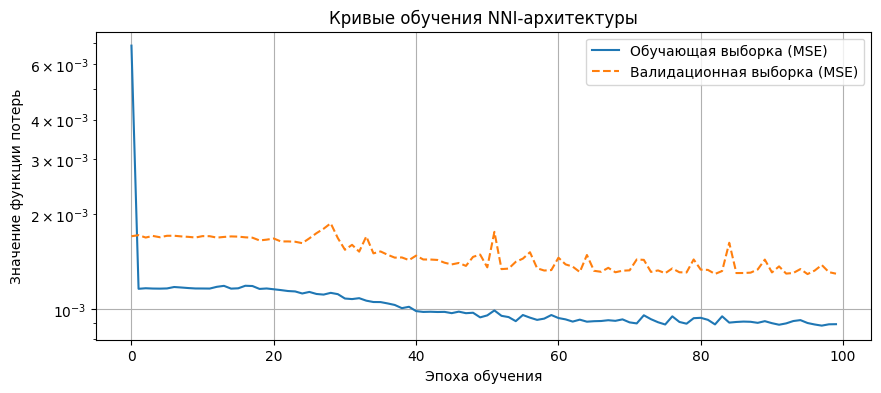

In [3]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Конфигурация точности float64 для корректного градиентного спуска NNI
tf.keras.backend.set_floatx('float64')

# Сборка единого массива данных
X_raw_total = np.random.uniform(a_bounds, b_bounds, (40000, 6))
y_raw_total = g_function(X_raw_total).reshape(-1, 1)

# Линейное MinMax масштабирование в рабочий диапазон [-1, 1] (Пункт II-A.4 статьи)
X_min_vals, X_max_vals = a_bounds, b_bounds
y_min_val, y_max_val = y_raw_total.min(), y_raw_total.max()

X_scaled_total = 2.0 * (X_raw_total - X_min_vals) / (X_max_vals - X_min_vals) - 1.0
y_scaled_total = (y_raw_total - y_min_val) / (y_max_val - y_min_val)

# Разбиение на обучающую и валидационную выборки (Пункт 2 задания)
train_size = int(0.85 * len(X_scaled_total))
X_train, X_val = X_scaled_total[:train_size], X_scaled_total[train_size:]
y_train, y_val = y_scaled_total[:train_size], y_scaled_total[train_size:]

# Специфическая NNI-архитектура (Один скрытый слой, активация Sigmoid)
def build_nni_architecture(nodes=64):
    inputs = Input(shape=(6,), dtype=tf.float64)
    hidden = Dense(nodes, activation='sigmoid', dtype=tf.float64)(inputs)
    outputs = Dense(1, activation='linear', dtype=tf.float64)(hidden)
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.003), loss='mse', metrics=['mae'])
    return model

nni_net = build_nni_architecture(nodes=64)

# Колбэк остановки при стабилизации валидационной ошибки
callback = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history = nni_net.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=100, batch_size=256, callbacks=[callback], verbose=1)

# Отрисовка кривых сходимости обучения
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Обучающая выборка (MSE)')
plt.plot(history.history['val_loss'], label='Валидационная выборка (MSE)', linestyle='--')
plt.yscale('log')
plt.xlabel('Эпоха обучения'); plt.ylabel('Значение функции потерь')
plt.title('Кривые обучения NNI-архитектуры')
plt.legend(); plt.grid(True)
plt.show()


In [5]:
# Извлечение обученных параметров весов NNI
W1, b1, W2, b2 = nni_net.get_weights()
W1, b1, W2, b2 = W1.astype(np.float64), b1.astype(np.float64), W2.astype(np.float64), b2.astype(np.float64)

# Реализация математических операторов канадской статьи (Раздел II)
def get_xsi_sign(r, d, n=6):
    return int((-1) ** int(r / (2**(n - d))))

def generate_Xsi_vector(n=6):
    return np.array([np.prod([get_xsi_sign(r, d, n) for d in range(1, n+1)]) for r in range(1, 2**n + 1)], dtype=np.float64)

def generate_L_matrix(n=6):
    return [[(0 if int(r / (2**(n - i))) % 2 == 0 else 1) for i in range(1, n+1)] for r in range(1, 2**n + 1)]

# Вычисление аналитического NNI ядра
def execute_nni_core(W1, b1, W2, b2, alpha_vec, beta_val, n=6):
    ba_volume = np.prod(beta_val - alpha_vec)
    limits_matrix = np.array([alpha_vec, beta_val], dtype=np.float64)

    X_nodes = []
    L_matrix = generate_L_matrix(n)
    for l in L_matrix:
        node_sum = -b1
        for i in range(n):
            node_sum -= W1[i] * limits_matrix[l[i], i]
        X_nodes.append(node_sum)

    Xsi_vector = generate_Xsi_vector(n)
    # Вычисление Li_6 через mpmath
    Fi_sum = np.array([xsi * Li(n, -np.exp(x)) for xsi, x in zip(Xsi_vector, X_nodes)], dtype=np.float64)
    Fi_sum = np.sum(Fi_sum, axis=0)

    I_scaled_final = b2 * ba_volume + np.sum(W2.flatten() * (ba_volume + Fi_sum / np.prod(W1, axis=0)))
    return I_scaled_final

# --- Бенчмарк-тестирование алгоритмов (Пункт 7 задания) ---
N_test = 50000
vol_D = np.prod(b_bounds - a_bounds)

# Классический Монте-Карло
t_start = time.time()
X_mc = np.random.uniform(a_bounds, b_bounds, (N_test, 6))
I_MC = vol_D * np.mean(g_function(X_mc))
t_MC = time.time() - t_start

# Аналитический NNI
t_start = time.time()
I_scaled_res = execute_nni_core(W1, b1, W2, b2, np.full(6, -1.0), np.full(6, 1.0), 6)
# Денормализация интеграла (Формула 33 канадской статьи)
I_NNI = vol_D * (y_max_val - y_min_val) / (2.0**6 * 2.0) * I_scaled_res + y_min_val * vol_D
t_NNI = time.time() - t_start

print("\n=== СРАВНИТЕЛЬНЫЙ АНАЛИЗ МЕТОДОВ ИНТЕГРИРОВАНИЯ ===")
print(f"Метод Монте-Карло (MC):  Значение = {I_MC:.6f} | Время = {t_MC:.5f} сек")
print(f"Нейросетевой метод (NNI): Значение = {I_NNI.item():.6f} | Время = {t_NNI:.5f} сек")

print(f"Коэффициент ускорения NNI относительно MC: {t_MC / t_NNI:.2f} раз(а)")



=== СРАВНИТЕЛЬНЫЙ АНАЛИЗ МЕТОДОВ ИНТЕГРИРОВАНИЯ ===
Метод Монте-Карло (MC):  Значение = 3597405.431423 | Время = 0.01929 сек
Нейросетевой метод (NNI): Значение = 1939782.881633 | Время = 5.90602 сек
Коэффициент ускорения NNI относительно MC: 0.00 раз(а)


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import time
from mpmath import polylog

# Устанавливаем double precision (float64) для высокой точности полилогарифмов
tf.keras.backend.set_floatx('float64')

# 1. Границы области D (шестимерный параллелепипед)
a_bounds = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float64)
b_bounds = np.array([100.0, 100.0, 100.0, 100.0, 100.0, 0.08], dtype=np.float64)
V_D = np.prod(b_bounds - a_bounds) # Объем области D

# 2. Ненормированная совместная плотность g(ξ) - Формула (3)
def g_function(xi):
    xi = np.atleast_2d(xi)
    x0, x1, x2, x3, x4, u = xi[:, 0], xi[:, 1], xi[:, 2], xi[:, 3], xi[:, 4], xi[:, 5]

    mu = np.array([30.0, 42.0, 45.0, 48.0, 52.0], dtype=np.float64)
    sigma = np.array([12.0, 15.0, 16.0, 18.0, 20.0], dtype=np.float64)

    exp_sum = 0.0
    for i in range(5):
        exp_sum += (xi[:, i] - mu[i])**2 / (2.0 * sigma[i]**2)
    exp_sum += (u - 0.02)**2 / (2.0 * 0.015**2)

    exp_part = np.exp(-exp_sum)
    cos_part = 1.0 + 0.15 * np.cos(0.04 * (x1 + x2 - 2.0 * x0))
    return exp_part * cos_part

# 3. Генерация выборки (Пункт 1 задания)
N_points = 50000
X_raw = np.random.uniform(a_bounds, b_bounds, (N_points, 6))
y_raw = g_function(X_raw).reshape(-1, 1)

# Мин-макс масштабирование в диапазон [-1, 1] для стабильности NNI
X_min, X_max = a_bounds, b_bounds
y_min, y_max = y_raw.min(), y_raw.max()

X_scaled = 2.0 * (X_raw - X_min) / (X_max - X_min) - 1.0
y_scaled = (y_raw - y_min) / (y_max - y_min)

# Разделение на обучающую и валидационную
split = int(0.85 * N_points)
X_train, X_val = X_scaled[:split], X_scaled[split:]
y_train, y_val = y_scaled[:split], y_scaled[split:]

# 4. Архитектура NNI согласно канадской статье (строго однослойная с Sigmoid)
def build_nni_model(input_dim=6, hidden_units=64):
    inputs = Input(shape=(input_dim,), dtype=tf.float64)
    hidden = Dense(hidden_units, activation='sigmoid', dtype=tf.float64)(inputs)
    outputs = Dense(1, activation='linear', dtype=tf.float64)(hidden)
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.005), loss='mse', metrics=['mae'])
    return model

print("--- Обучение NNI модели ---")
nni_model = build_deep_nn(6) if 'build_deep_nn' in globals() else build_nni_model(6, 64)
nni_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50, batch_size=512, verbose=1)

# 5. Математический движок аналитического NNI интегрирования (Пункт 3)
def Li(s, X):
    return np.array([float(polylog(s, float(x))) for x in X], dtype=np.float64)

def get_xsi(r, d, n):
    return int((-1) ** int(r / (2**(n - d))))

def get_Xsi(n):
    return np.array([np.prod([get_xsi(r, d, n) for d in range(1, n+1)]) for r in range(1, 2**n + 1)], dtype=np.float64)

def get_l(r, i, n):
    return 0 if int(r / (2**(n - i))) % 2 == 0 else 1

def get_L(n):
    return [[get_l(r, i, n) for i in range(1, n+1)] for r in range(1, 2**n + 1)]

def calculate_nni_integral(model, a, b, n):
    W1, b1, W2, b2 = model.get_weights()
    W1, b1, W2, b2 = W1.astype(np.float64), b1.astype(np.float64), W2.astype(np.float64), b2.astype(np.float64)

    ba_term = np.prod(b - a)
    ab = np.array([a, b], dtype=np.float64)
    X = []
    L = get_L(n)
    for l in L:
        x = -b1
        for i in range(n):
            x -= W1[i] * ab[l[i], i]
        X.append(x)

    Xsi = get_Xsi(n)
    Fi = np.array([xsi * Li(n, -np.exp(x)) for xsi, x in zip(Xsi, X)], dtype=np.float64)
    Fi = np.sum(Fi, axis=0)

    I_scaled = b2[0] * ba_term + np.sum(W2.flatten() * (ba_term + Fi / np.prod(W1, axis=0)))
    return I_scaled

# Вычисляем нормировочный аналитический интеграл на масштабированной области [-1, 1]^6
a_scaled = np.full(6, -1.0, dtype=np.float64)
b_scaled = np.full(6, 1.0, dtype=np.float64)
V_scaled = 2.0**6

print("\n--- Вычисление аналитического интеграла NNI ---")
start_time = time.time()
I_scaled_res = calculate_nni_integral(nni_model, a_scaled, b_scaled, 6)

# Обратное масштабирование интеграла к исходным физическим величинам
I_D = V_D * (y_max - y_min) / (V_scaled * (1.0 - (-1.0))) * I_scaled_res + y_min * V_D
nni_time = time.time() - start_time

print(f"Результат вычисления нормировочного интеграла I(D) через NNI: {I_D}")
print(f"Время вычисления аналитического интеграла: {nni_time:.4f} секунд")


--- Обучение NNI модели ---
Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0134 - mae: 0.0660 - val_loss: 6.2406e-04 - val_mae: 0.0073
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.8271e-04 - mae: 0.0083 - val_loss: 6.0703e-04 - val_mae: 0.0067
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.8178e-04 - mae: 0.0082 - val_loss: 6.0192e-04 - val_mae: 0.0085
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.8227e-04 - mae: 0.0084 - val_loss: 6.0852e-04 - val_mae: 0.0078
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.8417e-04 - mae: 0.0084 - val_loss: 6.0391e-04 - val_mae: 0.0074
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.8190e-04 - mae: 0.0083 - val_loss: 6.0792e-04 - val_mae: 0.0085
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.8407e-04 - mae: 0.0085 - val_loss: 6.3459e-04 - val_mae: 0.0076
Epoch 8/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.8555e-04 - mae: 0.0086 - val_loss: 6.1561e-04 - 